In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

from files.helpers import *
from files.ML_helpers import *


In [37]:
### CONTROLLER INPUT ###
# Define how many modes
amplitudes = [2, 4, 2, 1]
wave_numbers = [1, 2, 3, 5]
phases = [0, 0, 90, 0]

L = 60
C_CDL = 0.2
C_POPC = 1-C_CDL
n_bins = 100 # Number of bins for histogramming the shape distribution


In [38]:
# Write the .str file
write_str_file(amplitudes, wave_numbers, phases, L, C_CDL)

# Run TS2CG to generate the shape
run_ts2cg()

# Calculate curvature
point_dir = os.path.join(os.getcwd(), "point")
H, A, pos_dir = get_area_and_curvature(point_dir)

# Predict lateral organization
bin_range = (H.min(), H.max()) # My own preference
bin_centers = np.linspace(bin_range[0], bin_range[1], n_bins)
shape_density, bin_edges = np.histogram(H, bins=n_bins, range=bin_range, weights=A, density=True)
model, input_params, input_tensor_scaled = load_model_and_create_input(H, A, C_POPC, C_CDL, n_bins, bin_range)
phi_predict, rho_predict, probabilities = make_predictions(model, input_tensor_scaled, shape_density, C_POPC, C_CDL, input_params)


 Note (warning): lipid library file, is not provided, some lipids may not exist  

███████████████████████████████████████████████████████████████  
                      CG Membrane builder              
                         Version:  2.0  
███████████████████████████████████████████████████████████████  
---> attempting to obtain point data 
---> note: shape from 1D_PBC_Fourier will be made 
---> the point folder has been written 

Loading InnerBM.dat file...
Loading OuterBM.dat file...


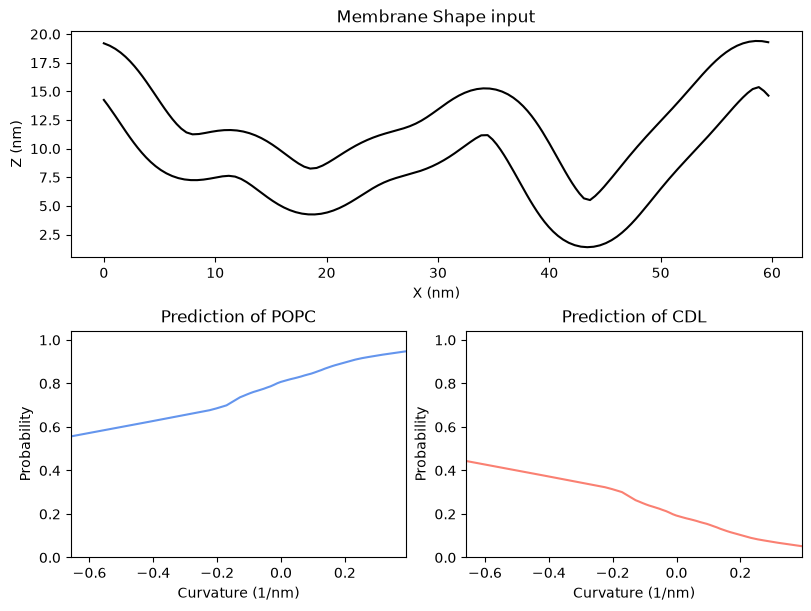

In [40]:
def plot_predictions(axs, bin_centers, probabilities, bin_range):
    colors = ["cornflowerblue", "salmon"]
    lipids = ["POPC", "CDL"]

    for i, ax in enumerate(axs):
        p = probabilities[:, i]
        mask = (p != 0) & np.isfinite(p)      # drop zeros and NaNs/infs
        ax.plot(bin_centers[mask], p[mask], color=colors[i])  # bin_centers stays untouched
        
    for i, a in enumerate(axs):
        a.set_xlabel("Curvature (1/nm)")
        a.set_ylabel("Probability")
        a.set_title(f"Prediction of {lipids[i]}")
        a.set_xlim(bin_range)
        a.set_ylim(0, max(probabilities[probabilities != 0]) * 1.1)  # Set y-limit to a bit above the max probability
    

def plot_shape_input(ax, pos_dir):
    for i, leaflet in enumerate(["Inner", "Outer"]):
        pos = pos_dir[leaflet]
        ax.plot(pos[:, 0], pos[:, 2], color="k")
    ax.set_xlabel("X (nm)")
    ax.set_ylabel("Z (nm)")
    ax.set_title("Membrane Shape input")

fig, ax = plt.subplot_mosaic("AAAA\nBBCC", figsize=(8, 6), constrained_layout=True)
plot_shape_input(ax["A"], pos_dir)
plot_predictions([ax["B"], ax["C"]], bin_centers, probabilities, bin_range)